Question 1

In [1]:

import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

testset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, num_workers=0
)

testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=0
)

classes = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')


Device: cuda


100%|██████████| 170M/170M [48:25<00:00, 58.7kB/s]


In [4]:

Din = 3 * 32 * 32
H = 100
K = 10

# Xavier initialization
W1 = torch.randn(Din, H, device=device) * (2 / (Din + H))**0.5
b1 = torch.zeros(H, device=device)

W2 = torch.randn(H, K, device=device) * (2 / (H + K))**0.5
b2 = torch.zeros(K, device=device)

lr = 0.1
lr_decay = 0.9
epochs = 10


In [5]:

def forward(x):
    # Hidden layer
    z1 = x @ W1 + b1
    h = torch.sigmoid(z1)

    # Output layer
    logits = h @ W2 + b2

    return h, logits


Q3) b)

In [6]:

def train_step(inputs, labels, lr):
    global W1, b1, W2, b2

    N = inputs.shape[0]
    x = inputs.reshape(N, -1)

    with torch.no_grad():
        # Forward propagation
        h, logits = forward(x)

        # Cross-entropy loss
        loss = F.cross_entropy(logits, labels)

        # Gradient of cross-entropy w.r.t. logits
        probs = torch.softmax(logits, dim=1)
        dlogits = probs.clone()
        dlogits[torch.arange(N, device=device), labels] -= 1
        dlogits /= N

        # Gradients for output layer
        dW2 = h.T @ dlogits
        db2 = dlogits.sum(dim=0)

        # Gradients for hidden layer
        dh = dlogits @ W2.T
        dz1 = dh * h * (1 - h)

        dW1 = x.T @ dz1
        db1 = dz1.sum(dim=0)

        # Parameter updates
        W1 -= lr * dW1
        b1 -= lr * db1

        W2 -= lr * dW2
        b2 -= lr * db2

    return loss.item()


In [7]:

def evaluate(loader):
    correct = 0
    total = 0
    total_loss = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            x = inputs.reshape(inputs.shape[0], -1)

            h, logits = forward(x)

            loss = F.cross_entropy(logits, labels)
            total_loss += loss.item() * labels.size(0)

            predicted = torch.argmax(logits, dim=1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total
    average_loss = total_loss / total

    return average_loss, accuracy


In [8]:

train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

for epoch in range(epochs):

    for inputs, labels in trainloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        train_step(inputs, labels, lr)

    # Evaluate using current parameters
    train_loss, train_acc = evaluate(trainloader)
    test_loss, test_acc = evaluate(testloader)

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Acc: {test_acc:.2f}%"
    )

    lr *= lr_decay


Epoch 1/10 | Train Loss: 1.6859 | Test Loss: 1.7065 | Train Acc: 41.21% | Test Acc: 40.22%
Epoch 2/10 | Train Loss: 1.6155 | Test Loss: 1.6489 | Train Acc: 44.25% | Test Acc: 42.83%
Epoch 3/10 | Train Loss: 1.5600 | Test Loss: 1.6115 | Train Acc: 46.58% | Test Acc: 44.72%
Epoch 4/10 | Train Loss: 1.5226 | Test Loss: 1.5892 | Train Acc: 47.24% | Test Acc: 45.27%
Epoch 5/10 | Train Loss: 1.4841 | Test Loss: 1.5731 | Train Acc: 49.40% | Test Acc: 45.90%
Epoch 6/10 | Train Loss: 1.4541 | Test Loss: 1.5510 | Train Acc: 50.28% | Test Acc: 46.43%
Epoch 7/10 | Train Loss: 1.4237 | Test Loss: 1.5342 | Train Acc: 51.42% | Test Acc: 47.10%
Epoch 8/10 | Train Loss: 1.4076 | Test Loss: 1.5304 | Train Acc: 51.79% | Test Acc: 47.09%
Epoch 9/10 | Train Loss: 1.3814 | Test Loss: 1.5185 | Train Acc: 53.04% | Test Acc: 47.51%
Epoch 10/10 | Train Loss: 1.3640 | Test Loss: 1.5134 | Train Acc: 53.47% | Test Acc: 47.83%


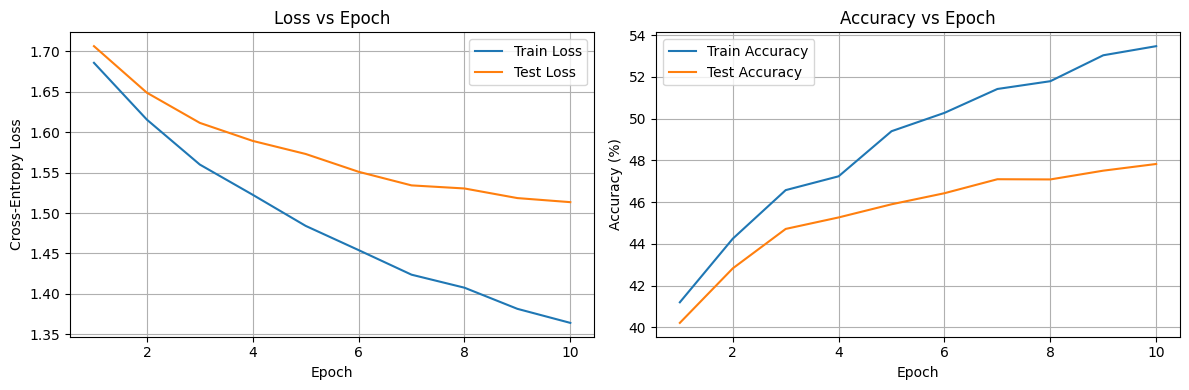

Final Training Accuracy: 53.47%
Final Test Accuracy: 47.83%


In [9]:

epochs_range = range(1, epochs + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, label="Train Loss")
plt.plot(epochs_range, test_losses, label="Test Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Loss vs Epoch")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_accuracies, label="Train Accuracy")
plt.plot(epochs_range, test_accuracies, label="Test Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy vs Epoch")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"Final Training Accuracy: {train_accuracies[-1]:.2f}%")
print(f"Final Test Accuracy: {test_accuracies[-1]:.2f}%")
